# 04 · Interface model: BRFSS binary, Gradient Boosting

The interface needs a model that is **small**, **fast** and gives **realistic probabilities**, because it will show people a risk percentage.

Design choices (different from notebook 03, and why):

| Choice | Reason |
|---|---|
| Gradient Boosting instead of Random Forest | Almost the same CV score on BRFSS (0.435 vs 0.443 macro-F1), but a model of about 1 MB instead of 165 MB |
| **No oversampling** | Oversampling inflates predicted probabilities. A user's risk should reflect the real rate of about 14%, not a 50/50 training set |
| Tune for ROC-AUC | Measures how well the model ranks people by risk, regardless of where the yes/no cut-off is |
| Choose the decision threshold by cross-validation | Gives a fair yes/no classification for macro-F1 without distorting the probabilities |

The test set is used once, at the end.

In [1]:
import sys, json, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss, f1_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, train_test_split

from src.models import PARAM_GRIDS, build_pipeline, test_report
from src.preprocess import RANDOM_STATE

PROCESSED, FIG_DIR, MODEL_DIR = ROOT / 'data/processed', ROOT / 'reports/figures', ROOT / 'models'
train, test = pd.read_csv(PROCESSED / 'brfss_bin_train.csv'), pd.read_csv(PROCESSED / 'brfss_bin_test.csv')
TARGET = 'Diabetes_binary'
X, y = train.drop(columns=TARGET), train[TARGET]
X_te, y_te = test.drop(columns=TARGET), test[TARGET]
print(X.shape, X_te.shape, f'diabetes rate {y.mean():.1%}')

(202944, 21) (50736, 21) diabetes rate 13.9%


## 1 · Tune hyperparameters (ROC-AUC, 60,000-row stratified sample, 3-fold CV)

In [2]:
Xs, _, ys, _ = train_test_split(X, y, train_size=60_000, stratify=y, random_state=RANDOM_STATE)
search = RandomizedSearchCV(build_pipeline('Gradient Boosting', 'none'), PARAM_GRIDS['Gradient Boosting'],
                            n_iter=20, scoring='roc_auc', cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                            random_state=RANDOM_STATE, n_jobs=1)
t = time.time(); search.fit(Xs, ys)
print(f'{time.time() - t:.0f}s  best CV ROC-AUC {search.best_score_:.4f}')
best_params = search.best_params_
best_params

154s  best CV ROC-AUC 0.8293


{'model__min_samples_leaf': 20,
 'model__max_leaf_nodes': 15,
 'model__max_iter': 400,
 'model__learning_rate': 0.03,
 'model__l2_regularization': 1.0}

## 2 · Choose the decision threshold

5-fold out-of-fold probabilities on the **full training set**: every person gets a prediction from a model that didn't see them. The threshold that maximises macro-F1 on these is used for yes/no classifications.

Best threshold 0.28: CV macro-F1 0.683 (at 0.50: 0.591)


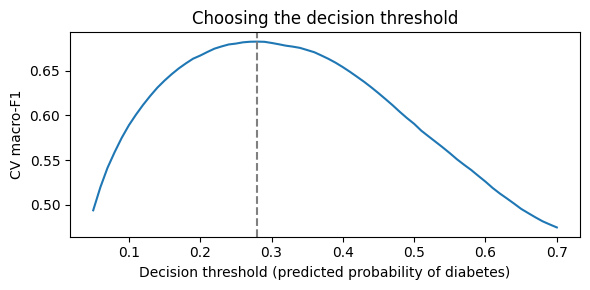

In [3]:
pipe = build_pipeline('Gradient Boosting', 'none').set_params(**best_params)
oof = cross_val_predict(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                        method='predict_proba')[:, 1]
thresholds = np.round(np.arange(0.05, 0.71, 0.01), 2)
f1s = [f1_score(y, oof >= t, average='macro') for t in thresholds]
THRESHOLD = float(thresholds[int(np.argmax(f1s))])
print(f'Best threshold {THRESHOLD:.2f}: CV macro-F1 {max(f1s):.3f} (at 0.50: {f1_score(y, oof >= 0.5, average="macro"):.3f})')

plt.figure(figsize=(6, 3))
plt.plot(thresholds, f1s)
plt.axvline(THRESHOLD, ls='--', c='grey')
plt.xlabel('Decision threshold (predicted probability of diabetes)'); plt.ylabel('CV macro-F1')
plt.title('Choosing the decision threshold'); plt.tight_layout()
plt.savefig(FIG_DIR / 'interface_threshold.png', dpi=200); plt.show()

## 3 · Fit on the full training set and evaluate once on the test set

In [4]:
t = time.time(); pipe.fit(X, y); print(f'fit {time.time() - t:.0f}s')

class Thresholded:
    """Uses the chosen threshold for yes/no predictions; probabilities are unchanged."""
    def __init__(self, pipe, threshold):
        self.pipe, self.threshold = pipe, threshold
    def predict_proba(self, X):
        return self.pipe.predict_proba(X)
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold).astype(int)

overall, per_class = test_report(Thresholded(pipe, THRESHOLD), X_te, y_te, {0: 'No diabetes', 1: 'Diabetes'})
proba_te = pipe.predict_proba(X_te)[:, 1]
overall['brier'] = brier_score_loss(y_te, proba_te)
print(overall.round(4)); print(); print(per_class.round(3))

fit 8s


macro_f1             0.6799
balanced_accuracy    0.6994
accuracy             0.8310
roc_auc              0.8271
brier                0.0974
dtype: float64

             recall    f1  support
No diabetes   0.882  0.90    43667
Diabetes      0.517  0.46     7069


In [5]:
rf = json.loads((ROOT / 'reports/final_models.json').read_text())['brfss_bin']['test']
comparison = pd.DataFrame({
    'Random Forest + oversampling (notebook 03)': rf,
    'Gradient Boosting, interface model': overall[['macro_f1', 'balanced_accuracy', 'accuracy', 'roc_auc']].to_dict(),
}).T
comparison.round(3)

,macro_f1,balanced_accuracy,accuracy,roc_auc
Random Forest + oversampling (notebook 03),0.662,0.724,0.788,0.818
"Gradient Boosting, interface model",0.680,0.699,0.831,0.827


## 4 · Are the probabilities realistic?

A calibration curve compares predicted risk with the observed rate. Points on the diagonal mean a predicted 30% risk really corresponds to about 30% of people having diabetes.

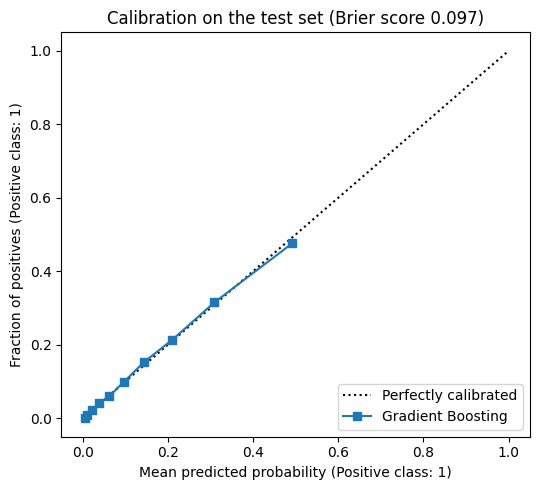

Mean predicted risk 13.9% vs actual rate 13.9%


In [6]:
fig, ax = plt.subplots(figsize=(5.5, 5))
CalibrationDisplay.from_predictions(y_te, proba_te, n_bins=10, strategy='quantile', ax=ax, name='Gradient Boosting')
ax.set_title(f'Calibration on the test set (Brier score {overall["brier"]:.3f})')
plt.tight_layout(); plt.savefig(FIG_DIR / 'interface_calibration.png', dpi=200); plt.show()
print(f'Mean predicted risk {proba_te.mean():.1%} vs actual rate {y_te.mean():.1%}')

## 5 · Save the interface model

In [7]:
path = MODEL_DIR / 'interface_brfss_bin_gb.joblib'
joblib.dump(pipe, path, compress=3)
meta = {
    'dataset': 'BRFSS 2015, binary (diabetes vs not; prediabetes counted as not)',
    'model': 'Gradient Boosting (HistGradientBoostingClassifier)', 'imbalance': 'none',
    'params': {k: (v.item() if hasattr(v, 'item') else v) for k, v in best_params.items()},
    'threshold': THRESHOLD, 'features': list(X.columns),
    'base_rate': float(y.mean()),
    'test': {k: round(float(v), 4) for k, v in overall.items()},
    'size_mb': round(path.stat().st_size / 1e6, 2),
}
(MODEL_DIR / 'interface_brfss_bin_gb.json').write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

{
  "dataset": "BRFSS 2015, binary (diabetes vs not; prediabetes counted as not)",
  "model": "Gradient Boosting (HistGradientBoostingClassifier)",
  "imbalance": "none",
  "params": {
    "model__min_samples_leaf": 20,
    "model__max_leaf_nodes": 15,
    "model__max_iter": 400,
    "model__learning_rate": 0.03,
    "model__l2_regularization": 1.0
  },
  "threshold": 0.28,
  "features": [
    "HighBP",
    "HighChol",
    "CholCheck",
    "BMI",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income"
  ],
  "base_rate": 0.13933400346893723,
  "test": {
    "macro_f1": 0.6799,
    "balanced_accuracy": 0.6994,
    "accuracy": 0.831,
    "roc_auc": 0.8271,
    "brier": 0.0974
  },
  "size_mb": 0.22
}


## Findings

- **Better and far smaller.** On the test set, Gradient Boosting without oversampling scores a macro-F1 of **0.680** (Random Forest + oversampling: 0.662), accuracy **0.831** (0.788) and ROC-AUC **0.827** (0.818). The file is **0.22 MB**; the Random Forest was 123 MB.
- **Realistic probabilities.** The calibration curve sits on the diagonal (Brier score 0.097), and the average predicted risk equals the actual rate (13.9%). This is what makes it safe to show users a risk percentage.
- **Threshold.** A cut-off of **0.28** (chosen on training data only) gives the best macro-F1. At the default 0.50 the model would miss most people with diabetes (CV macro-F1 0.59). In the interface, "higher risk" means a predicted risk of 28% or more, about twice the average.
- **Still limited.** Recall for diabetes is 0.52: half of the people with diabetes are not flagged. Survey answers alone can't do better than this. The interface must say clearly that it isn't a diagnosis.
